In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq, root
R = 8.314462618
print('Ready: NumPy, Matplotlib, SciPy')

Ready: NumPy, Matplotlib, SciPy


##Diffuse-interface representation


w=1.0, 10-90 thickness=2.197, E_grad=0.16660
w=2.0, 10-90 thickness=4.394, E_grad=0.08332
w=4.0, 10-90 thickness=8.789, E_grad=0.04167


/tmp/ipykernel_452/391299849.py:13: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  E_grad = np.trapz(grad_energy, s)


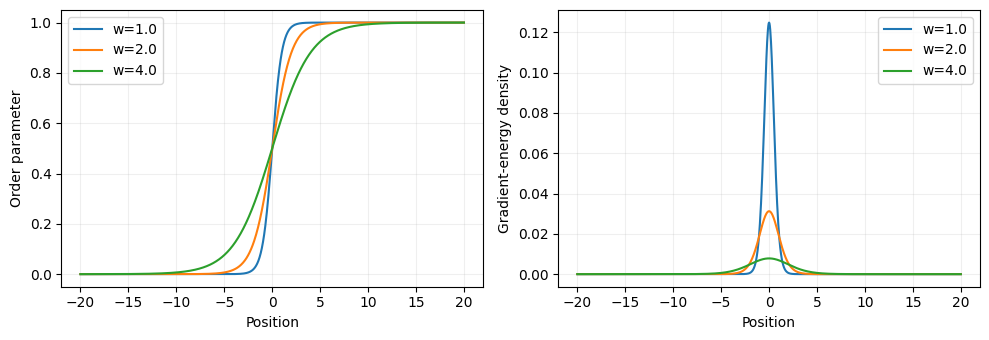

In [ ]:

s = np.linspace(-20, 20, 1001)
widths = [1., 2., 4.]
kappa_interface = 1.
fig, axes = plt.subplots(1, 2, figsize=(10,3.5))
for w in widths:

    phi = 0.5 * (1.0 + np.tanh(s / w))

    dphi_ds = np.gradient(phi, s)
    grad_energy = 0.5*kappa_interface*dphi_ds**2

    E_grad = np.trapz(grad_energy, s)
    print(f'w={w:.1f}, 10-90 thickness={2*w*np.arctanh(0.8):.3f}, E_grad={E_grad:.5f}')
    axes[0].plot(s, phi, label=f'w={w}')
    axes[1].plot(s, grad_energy, label=f'w={w}')
axes[0].set(xlabel='Position', ylabel='Order parameter')
axes[1].set(xlabel='Position', ylabel='Gradient-energy density')
for ax in axes: ax.legend(); ax.grid(alpha=.2)
plt.tight_layout(); plt.show()

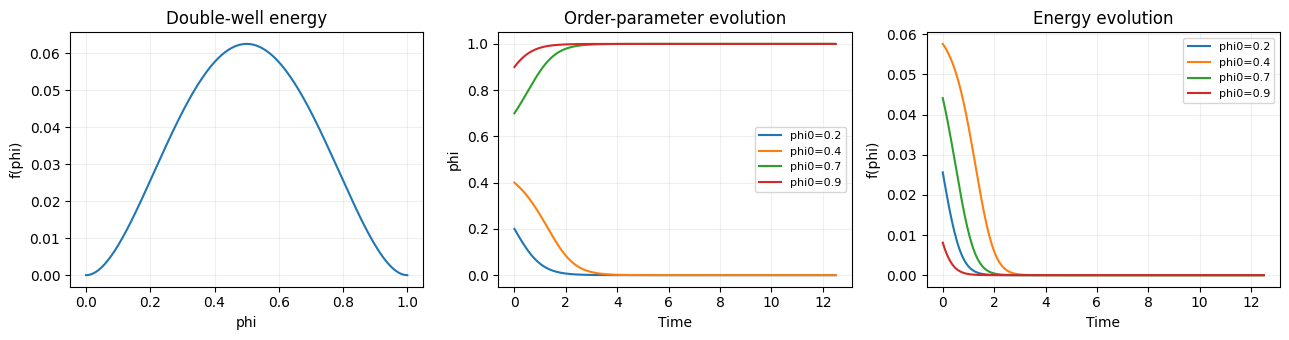

In [ ]:

W = 1.0
L_ac = 1.0
dt_ac = 0.05
nsteps_ac = 250
initial_phi = [0.2, 0.4, 0.7, 0.9]

def bulk_energy(phi):

    return W * phi**2 * (1 - phi)**2

def dfbulk_dphi(phi):

    return 2 * W * phi * (1 - phi) * (1 - 2 * phi)

def allen_cahn_uniform(phi0, dt=dt_ac, nsteps=nsteps_ac):
    values = np.empty(nsteps+1)
    values[0] = phi0
    for n in range(nsteps):

        values[n+1] = values[n] - L_ac * dfbulk_dphi(values[n]) * dt
    return values

phi_grid = np.linspace(0,1,301)
times = np.arange(nsteps_ac+1)*dt_ac
fig, ax = plt.subplots(1,3,figsize=(13,3.5))
ax[0].plot(phi_grid,bulk_energy(phi_grid))
for p0 in initial_phi:
    trajectory = allen_cahn_uniform(p0)
    ax[1].plot(times,trajectory,label=f'phi0={p0}')
    ax[2].plot(times,bulk_energy(trajectory),label=f'phi0={p0}')
ax[0].set(xlabel='phi',ylabel='f(phi)',title='Double-well energy')
ax[1].set(xlabel='Time',ylabel='phi',title='Order-parameter evolution')
ax[2].set(xlabel='Time',ylabel='f(phi)',title='Energy evolution')
for a in ax: a.grid(alpha=.2)
ax[1].legend(fontsize=8); ax[2].legend(fontsize=8); plt.tight_layout();plt.show()

##Cu–Ni FCC chemical free energy


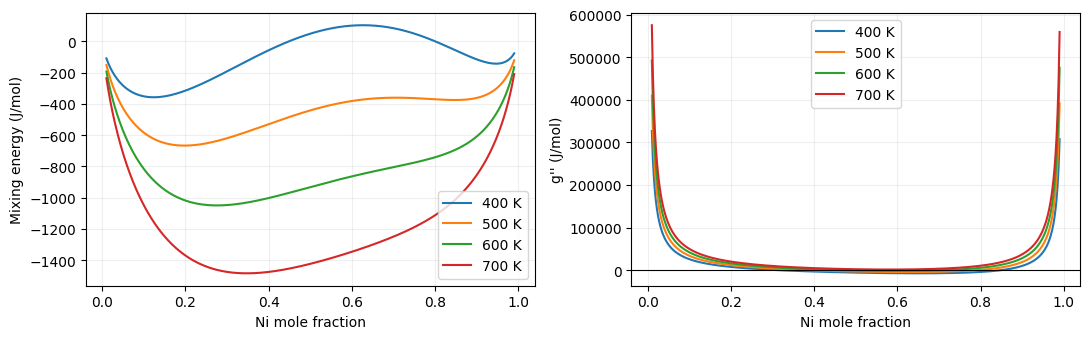

In [ ]:
def interaction_parameters(T):

    L0 = 8047.72 + 3.42217 * T
    L1 = -2041.3 + 0.99714 * T
    return L0, L1

def g_mix(x, T):
    x = np.clip(np.asarray(x), 1e-8, 1 - 1e-8)
    L0, L1 = interaction_parameters(T)

    return R * T * (x * np.log(x) + (1 - x) * np.log(1 - x)) + x * (1 - x) * (L0 + L1 * (1 - 2 * x))

def dgdx(x, T):
    x = np.clip(np.asarray(x), 1e-8, 1 - 1e-8)
    L0, L1 = interaction_parameters(T)

    return R * T * np.log(x / (1 - x)) + (1 - 2 * x) * L0 + (1 - 6 * x + 6 * x**2) * L1

def d2gdx2(x, T):
    x = np.clip(np.asarray(x), 1e-8, 1 - 1e-8)
    L0, L1 = interaction_parameters(T)

    return R * T / (x * (1 - x)) - 2 * L0 + (12 * x - 6) * L1

xx = np.linspace(.01, .99, 400)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for T in [400, 500, 600, 700]:
    axes[0].plot(xx, g_mix(xx, T), label=f'{T} K')
    axes[1].plot(xx, d2gdx2(xx, T), label=f'{T} K')
axes[1].axhline(0, color='k', lw=.8)
axes[0].set(xlabel='Ni mole fraction', ylabel='Mixing energy (J/mol)')
axes[1].set(xlabel='Ni mole fraction', ylabel="g'' (J/mol)")
for ax in axes: ax.legend(); ax.grid(alpha=.2)
plt.tight_layout(); plt.show()

##Spinodal curve


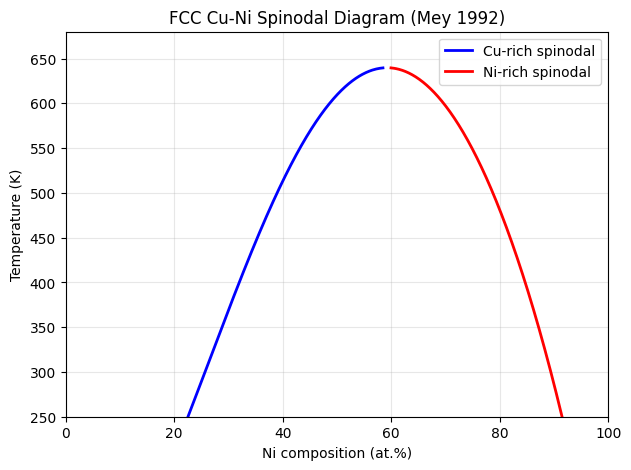

In [ ]:
def spinodal_roots(T):
    grid=np.linspace(.001,.999,1000)
    values=d2gdx2(grid,T)
    roots=[]
    for i in range(len(grid)-1):
        if values[i]*values[i+1]<0:
            roots.append(brentq(lambda x:d2gdx2(x,T),grid[i],grid[i+1]))
    return roots

# Below, loop through T=250...650 K, retain temperatures with two roots,
# and plot Cu-rich and Ni-rich spinodal branches.
T_values = np.linspace(250, 650, 1000)

T_spinodal = []
x_Cu_rich = []
x_Ni_rich = []

for T in T_values:
    roots = spinodal_roots(T)


    if len(roots) == 2:
        T_spinodal.append(T)
        x_Cu_rich.append(roots[0])
        x_Ni_rich.append(roots[1])


plt.figure(figsize=(7, 5))

plt.plot(np.array(x_Cu_rich)*100, T_spinodal,
         'b-', linewidth=2, label='Cu-rich spinodal')

plt.plot(np.array(x_Ni_rich)*100, T_spinodal,
         'r-', linewidth=2, label='Ni-rich spinodal')

plt.xlabel('Ni composition (at.%)')
plt.ylabel('Temperature (K)')
plt.title('FCC Cu-Ni Spinodal Diagram (Mey 1992)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.xlim(0, 100)
plt.ylim(250, 680)
plt.show()


##2D Cahn–Hilliard finite-difference solver


In [ ]:
N=64
dx=1.0
kappa_star=.25
Gscale=1.0e4
rng=np.random.default_rng(6756)

def initialize(x0,noise=.01):
    x=x0+noise*rng.standard_normal((N,N))
    x+=x0-x.mean()
    return x

def laplacian_fd(u,dx=dx):

    u_right = np.roll(u, -1, axis=1)
    u_left = np.roll(u, 1, axis=1)
    u_down = np.roll(u, -1, axis=0)
    u_up = np.roll(u, 1, axis=0)
    return (u_right + u_left + u_down + u_up - 4.0 * u) / (dx**2)

def fprime(x,T):

    return dgdx(x, T) / Gscale

def chemical_potential(x,T):

    return fprime(x, T) - kappa_star * laplacian_fd(x)

def ch_step_fd(x,T,dt):

    mu = chemical_potential(x, T)
    dxdt = laplacian_fd(mu)
    # explicit Euler update
    return x + dt * dxdt

def energy_density_fd(x,T):

    gx = (np.roll(x, -1, axis=1) - np.roll(x, 1, axis=1)) / (2.0 * dx)
    gy = (np.roll(x, -1, axis=0) - np.roll(x, 1, axis=0)) / (2.0 * dx)
    return np.mean(g_mix(x,T)/Gscale+0.5*kappa_star*(gx**2+gy**2))

def simulate_fd(T,x0,dt,nsteps,save_every):
    x=initialize(x0)
    snapshots=[x.copy()]
    history=[(0,float(x.mean()),energy_density_fd(x,T),float(x.min()),float(x.max()))]
    for step in range(1,nsteps+1):
        x=ch_step_fd(x,T,dt)
        if not np.all(np.isfinite(x)) or x.min() < -.05 or x.max()>1.05:
            raise RuntimeError(f'Instability at step {step}: reduce dt')
        if step%save_every==0:
            snapshots.append(x.copy())
            history.append((step,float(x.mean()),energy_density_fd(x,T),float(x.min()),float(x.max())))
    return np.array(snapshots),np.array(history)

##Validation and numerical experiments


**Baseline:** 500 K, $x_0=0.60$, $N=64$, $\Delta\tau=0.005$, 10000 steps.

Laplacian constant max error: 0.0
Laplacian periodic sum: 5.1514348342607263e-14
Simulation completed.
Snapshots shape: (11, 64, 64)
History shape: (11, 5)
Initial average composition: 0.5999999999999999
Final average composition: 0.5999999999999999
Change in average composition: 0.0
Initial free energy: -0.038177701018600546
Final free energy: -0.04151688193718689


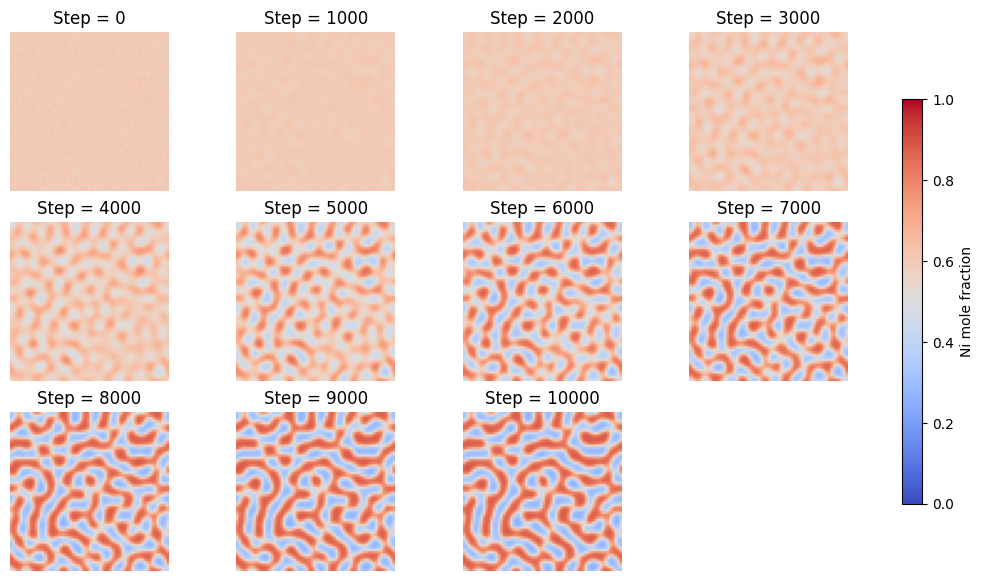

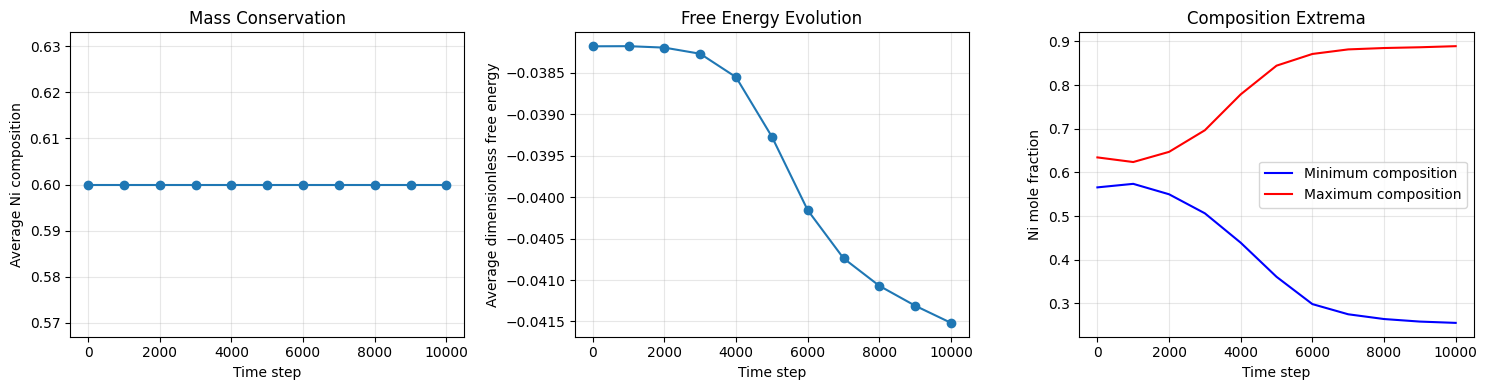

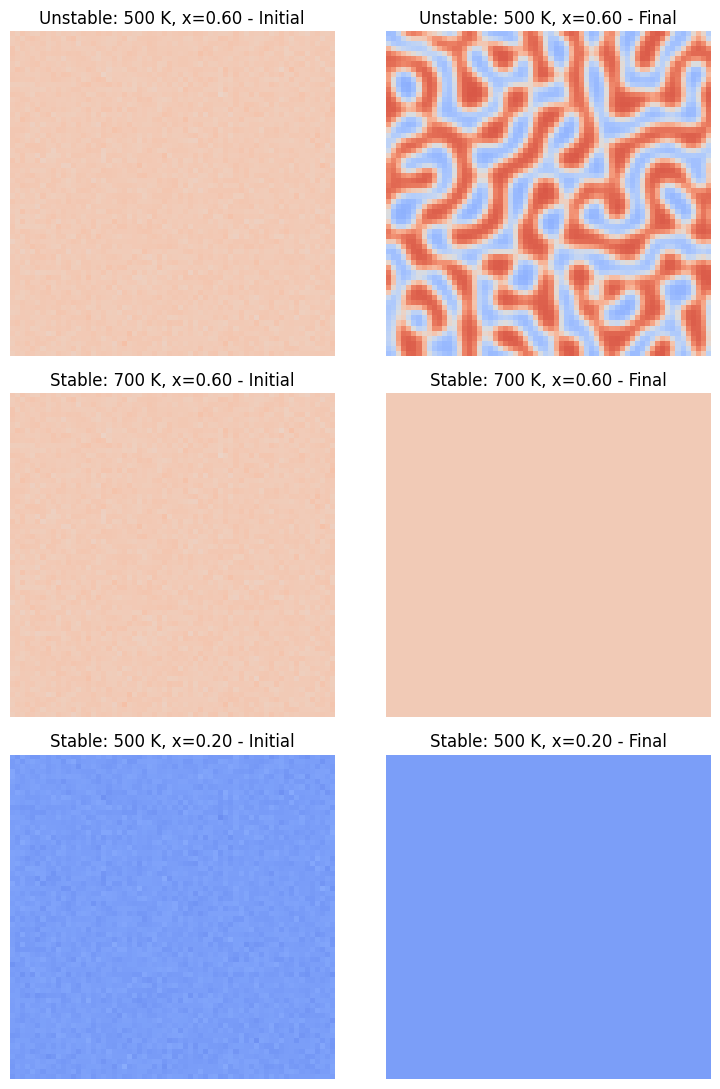

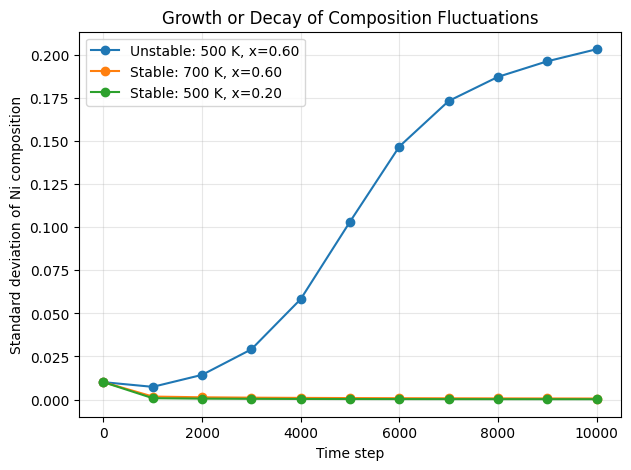

In [ ]:
# D1: Diagnostic tests

constant_field = np.ones((N, N))
error = np.abs(laplacian_fd(constant_field)).max()

print("Laplacian constant max error:", error)

#Sum of Laplacian with periodic boundaries
test = rng.standard_normal((N, N))
lap_sum = laplacian_fd(test).sum()

print("Laplacian periodic sum:", lap_sum)

#Baseline simulation

snapshots, history = simulate_fd(
    T=500,
    x0=0.60,
    dt=0.005,
    nsteps=10000,
    save_every=1000
)

print("Simulation completed.")
print("Snapshots shape:", snapshots.shape)
print("History shape:", history.shape)

print("Initial average composition:", history[0, 1])
print("Final average composition:", history[-1, 1])
print("Change in average composition:",
      history[-1, 1] - history[0, 1])

print("Initial free energy:", history[0, 2])
print("Final free energy:", history[-1, 2])



fig, axes = plt.subplots(3, 4, figsize=(14, 7))

for i, ax in enumerate(axes.flat):

    if i < len(snapshots):
        im = ax.imshow(
            snapshots[i],
            cmap='coolwarm',
            vmin=0,
            vmax=1,
            origin='lower'
        )

        ax.set_title(f'Step = {int(history[i,0])}')
        ax.axis('off')

    else:
        ax.axis('off')

fig.colorbar(im, ax=axes.ravel().tolist(),
             shrink=0.75, label='Ni mole fraction')

plt.show()




fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Average composition
axes[0].plot(history[:,0], history[:,1], 'o-')
axes[0].set_xlabel('Time step')
axes[0].set_ylabel('Average Ni composition')
axes[0].set_title('Mass Conservation')
axes[0].grid(alpha=0.3)

# Total free energy
axes[1].plot(history[:,0], history[:,2], 'o-')
axes[1].set_xlabel('Time step')
axes[1].set_ylabel('Average dimensionless free energy')
axes[1].set_title('Free Energy Evolution')
axes[1].grid(alpha=0.3)

# Minimum and maximum compositions
axes[2].plot(history[:,0], history[:,3],
             'b-', label='Minimum composition')
axes[2].plot(history[:,0], history[:,4],
             'r-', label='Maximum composition')

axes[2].set_xlabel('Time step')
axes[2].set_ylabel('Ni mole fraction')
axes[2].set_title('Composition Extrema')
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

#Comparison of stable and unstable conditions

cases = [
    (500, 0.60, "Unstable: 500 K, x=0.60"),
    (700, 0.60, "Stable: 700 K, x=0.60"),
    (500, 0.20, "Stable: 500 K, x=0.20")
]

results = []

for T, x0, label in cases:

    # Reset random seed for identical fluctuation patterns
    rng = np.random.default_rng(6756)

    s, h = simulate_fd(
        T=T,
        x0=x0,
        dt=0.005,
        nsteps= 10000,
        save_every=1000
    )

    results.append((label, s, h))

# Plot initial and final microstructures
fig, axes = plt.subplots(3, 2, figsize=(8, 11))

for i, (label, s, h) in enumerate(results):

    axes[i,0].imshow(
        s[0], cmap='coolwarm',
        vmin=0, vmax=1
    )
    axes[i,0].set_title(label + " - Initial")

    axes[i,1].imshow(
        s[-1], cmap='coolwarm',
        vmin=0, vmax=1
    )
    axes[i,1].set_title(label + " - Final")

    for ax in axes[i]:
        ax.axis('off')

plt.tight_layout()
plt.show()


# Comparing composition fluctuations
plt.figure(figsize=(7, 5))

for label, s, h in results:

    std = np.std(s, axis=(1,2))

    plt.plot(h[:,0], std, 'o-', label=label)

plt.xlabel('Time step')
plt.ylabel('Standard deviation of Ni composition')
plt.title('Growth or Decay of Composition Fluctuations')
plt.legend()
plt.grid(alpha=0.3)
plt.show()